# Figure 4: The international network of scientific citation preferences controlling for publication journal

This notebook reproduces Fig. 4: (A) odds ratios of the multinomial logit model predicting the journal bootstrap citation preferences, and (B) the journal bootstrap network filtered to positive relationships.

The journal bootstrap citation preferences (mean AUC and standard deviation over 100 bootstrap samples of the cited articles stratified by journal) are computed in **2_GlobalCitationNetwork_citationpreferences**. It reads its input from the data folder (`path2data`).

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from vizutils import pvalue2stars, table_row, make_multinomial_latex_table, logistic_odds_ratio_plot

import pyscisci.all as pyscisci

# set this path to where the OpenAlex database is stored
path2openalex = '/Users/hgt6rn/Documents/DataSets/OpenAlex'

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the network picture of Fig. 4B is stored with the figures of the paper
path2paperfigures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'paper', 'Figures')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

Please install python-Levenshtein to take full advantage of the NLP tools. 
 pip install python-Levenshtein
Please install sparse_dot_topn to take full advantage of the NLP tools. 
 pip install sparse_dot_topn


/Users/psp2nq/anaconda3/lib/python3.11/site-packages/dask/dataframe/__init__.py:49: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


# Journal bootstrap citation preference network

In [2]:
bootstrap_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_journalbootstrap_auc.csv.gz'))

# the bootstrap citation preference: AUC and STD are the mean and standard deviation over the bootstrap samples
country_auc_df = bootstrap_auc_df.copy()
country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/country_auc_df['STD']

country_auc_df = country_auc_df[country_auc_df['N']>=50].reset_index(drop=True)
# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

In [3]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net_boot = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')

cumulative_net_boot['SourceCommunity'] = cumulative_net_boot['CitingCountry'].map(country2comm)
cumulative_net_boot['TargetCommunity'] = cumulative_net_boot['CitedCountry'].map(country2comm)

print(cumulative_net_boot.shape, "edges")
pcumnet = cumulative_net_boot[cumulative_net_boot['Zscore'] > 0]
print(pcumnet.shape, "positive edges")
ncumnet = cumulative_net_boot[cumulative_net_boot['Zscore'] < 0]
print(ncumnet.shape, "negative edges")

(1011, 12) edges
(663, 12) positive edges
(348, 12) negative edges


## Comparison of the original (N1) and journal bootstrap (N2) networks

Both networks are built the same way: country pairs with N >= 50, Holm-Sidak correction with alpha = 0.01 within each year, 1990-2017, and each country pair keeps its most recent significant citation preference. N1 is the main network of Fig. 2 and Supplementary Table S3 (536 positive and 1,471 negative edges).

In [4]:
from sourcedatautils import load_country_auc, load_net_auc, cumulative_network

# N1: the original cumulative network; N2: the cumulative journal bootstrap network
n1 = cumulative_network(load_net_auc(load_country_auc()))
n2 = cumulative_net_boot

pair = ['CitingCountry', 'CitedCountry']
pos1, pos2 = n1[n1['Zscore'] > 0][pair], n2[n2['Zscore'] > 0][pair]
neg1, neg2 = n1[n1['Zscore'] < 0][pair], n2[n2['Zscore'] < 0][pair]
shared_pos, shared_neg = len(pos1.merge(pos2)), len(neg1.merge(neg2))

# positive edges of N2 that are not in N1, and the countries they concentrate on
new_pos = pos2.merge(pos1, how='left', indicator=True)
new_pos = new_pos[new_pos['_merge'] == 'left_only']
top_targets = new_pos['CitedCountry'].value_counts().head(11)
top_sources = new_pos['CitingCountry'].value_counts().head(7)

def community_shares(net):
    # edges to or from a country without a community count as between communities
    source, target = net['CitingCountry'].map(country2comm), net['CitedCountry'].map(country2comm)
    within = (source == target) & source.notna()
    return within[net['Zscore'] > 0].mean(), (~within)[net['Zscore'] < 0].mean()

within1, between1 = community_shares(n1)
within2, between2 = community_shares(n2)

comparison = pd.DataFrame([
    ['Positive edges', len(pos1), len(pos2)],
    ['Negative edges', len(neg1), len(neg2)],
    ['Positive edges in both networks', shared_pos, shared_pos],
    ['Negative edges in both networks', shared_neg, shared_neg],
    ['Share of positive edges within the same community', round(within1, 3), round(within2, 3)],
    ['Share of negative edges between communities', round(between1, 3), round(between2, 3)],
    ], columns=['Measure', 'N1', 'N2'])
print(comparison.to_string(index=False))
print('shared positive edges: {:.0%} of N1, {:.0%} of N2'.format(shared_pos/len(pos1), shared_pos/len(pos2)))
print('shared negative edges: {:.0%} of N1, {:.0%} of N2'.format(shared_neg/len(neg1), shared_neg/len(neg2)))
print('negative edges: {:.0%} fewer in N2'.format(1 - len(neg2)/len(neg1)))
print('{} new positive edges in N2: {:.0%} to 11 countries ({}), {:.0%} from 7 countries ({})'.format(
    len(new_pos), top_targets.sum()/len(new_pos), ', '.join(top_targets.index),
    top_sources.sum()/len(new_pos), ', '.join(top_sources.index)))

                                          Measure       N1      N2
                                   Positive edges  536.000 663.000
                                   Negative edges 1471.000 348.000
                  Positive edges in both networks  447.000 447.000
                  Negative edges in both networks  332.000 332.000
Share of positive edges within the same community    0.659   0.599
      Share of negative edges between communities    0.862   0.856
shared positive edges: 83% of N1, 67% of N2
shared negative edges: 23% of N1, 95% of N2
negative edges: 76% fewer in N2
216 new positive edges in N2: 46% to 11 countries (AU, IT, ES, FI, GB, NO, MY, IN, IE, PK, CA), 27% from 7 countries (MX, CO, RU, PT, PL, FR, BR)


# Multinomial logit model with temporal fixed-effects

In [5]:
panel_data = pd.read_csv(os.path.join(path2data, 'link_prediction_panel_data_1990_2017.csv.gz'))

strat_net_panel = panel_data.merge(net_auc.rename(columns={'CitingCountry':'oCountry', 'CitedCountry':'tCountry', 'CitedYear':'year'}), 
                           how='left', on=['oCountry','tCountry','year'])

strat_net_panel['edge_preference'] = 1 + (strat_net_panel['Zscore'] < 0).astype(int)
strat_net_panel.loc[strat_net_panel['Significant'].isnull(), 'edge_preference'] = 0

In [6]:
model_features = ['oGDP_PCAP','tGDP_PCAP','oPop','tPop','PhysicalDistance', 'TopicSimilarity',
                  'oTopFrac','tTopFrac','CollabStrength', 'cumulative_laws']

dependent_var = 'edge_preference'

dummy_years=['year_'+str(i) for i in range(syear + 1, eyear + 1)]

all_dummies=['comlang_off','SameContinent']+dummy_years


# the citation preferences cover 1990-2017, so the panel rows of other years are not used
net_panel_with_dummies = pd.get_dummies(strat_net_panel[(strat_net_panel['year'] >= syear) & (strat_net_panel['year'] <= eyear)], prefix='year', columns=['year'], drop_first=True)
net_panel_with_dummies[dummy_years] = net_panel_with_dummies[dummy_years].astype(int)


net_panel_with_dummies = net_panel_with_dummies[[dependent_var] + model_features + all_dummies]

# continuous variables are standardized once over the 1990-2017 panel, so all models share the same scale (as in Fig. 3)
for c in model_features:
    net_panel_with_dummies[c] = (net_panel_with_dummies[c] - net_panel_with_dummies[c].mean())/net_panel_with_dummies[c].std()

v1=['oGDP_PCAP','tGDP_PCAP', 'oPop','tPop']
v2=['PhysicalDistance','SameContinent']
v3=['comlang_off','TopicSimilarity']
v4=['cumulative_laws']
v5=['CollabStrength']
v6=['oTopFrac','tTopFrac']

exog_var_sets = [v1,v2,v3,v4,v5,v6]
dep_var = "edge_preference"

Nmodels = len(exog_var_sets)

fit_models = []
for icol in range(Nmodels):
    exog_vars = dummy_years + list(chain.from_iterable(exog_var_sets[:(icol+1)]))
    X = net_panel_with_dummies[exog_vars + [dep_var]].dropna().reset_index(drop=True)

    Y = X[dep_var]
    X = sm.add_constant(X[exog_vars])

    model = sm.MNLogit(Y, X).fit(maxiter=50)
    fit_models.append(model)

Optimization terminated successfully.
         Current function value: 0.019836
         Iterations 14
Optimization terminated successfully.
         Current function value: 0.018698
         Iterations 14
Optimization terminated successfully.
         Current function value: 0.017553
         Iterations 14
Optimization terminated successfully.
         Current function value: 0.017471
         Iterations 14
Optimization terminated successfully.
         Current function value: 0.015468
         Iterations 14
Optimization terminated successfully.
         Current function value: 0.015076
         Iterations 14


## Supplementary Table S10

In [7]:
# the LaTeX tables are saved in the tables folder
path2tables = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'tables')
os.makedirs(path2tables, exist_ok=True)

namedict_s10 = {'const':'Intercept', 'oTopFrac':'Origin top journal fraction', 'tTopFrac':'Target top journal fraction',
                'oGDP_PCAP':'Log origin GDP per capita', 'oPop':'Log origin population', 'tPop':'Log target population',
                'tGDP_PCAP':'Log target GDP per capita', 'PhysicalDistance':'Physical distance', 'TopicSimilarity':'Field similarity',
                'comlang_off':'Same official language', 'CollabStrength':'Log collaboration strength', 'SameContinent':'Same continent',
                'cumulative_laws':'Bilateral research agreements'}

make_multinomial_latex_table(fit_models, exog_var_sets, dep_var, namedict_s10,
                             caption_text="Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap.",
                             label="table:multinomialfull_bootstrap", fname=os.path.join(path2tables, "TableS10.tex"))

{\tiny
    \begin{longtable}{p{0.2\linewidth}p{0.12\linewidth}p{0.12\linewidth}p{0.12\linewidth}p{0.12\linewidth}p{0.12\linewidth}p{0.12\linewidth}}\caption{\textbf{Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap.} Model coefficients (log-odds of a positive or negative citation preference relative to no preference) with 95\% confidence intervals in parentheses, followed by the standard error (S.E.) and the exact $p$-value. $p$-values are from two-sided Wald $z$-tests of each coefficient, without adjustment for multiple comparisons. The LLR $\chi^2$ is a likelihood-ratio test against the intercept-only model.} 
      \label{table:multinomialfull_bootstrap} \\
      \hline \hline \\
    \multicolumn{7}{c}{\textbf{Dependent variable: Citation preference}} \\ \hline 
     & \multicolumn{6}{c}{Model}  \\\cline{2-7}& (1)& (2)& (3)& (4)& (5)& (6)\\[0.8ex]
    \hline
    \endfirsthead\multicolumn{2}{c}%
      {{\tablename\ \thetable{} -- continued from pre

'{\\tiny\n    \\begin{longtable}{p{0.2\\linewidth}p{0.12\\linewidth}p{0.12\\linewidth}p{0.12\\linewidth}p{0.12\\linewidth}p{0.12\\linewidth}p{0.12\\linewidth}}\\caption{\\textbf{Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap.} Model coefficients (log-odds of a positive or negative citation preference relative to no preference) with 95\\% confidence intervals in parentheses, followed by the standard error (S.E.) and the exact $p$-value. $p$-values are from two-sided Wald $z$-tests of each coefficient, without adjustment for multiple comparisons. The LLR $\\chi^2$ is a likelihood-ratio test against the intercept-only model.} \n      \\label{table:multinomialfull_bootstrap} \\\\\n      \\hline \\hline \\\\\n    \\multicolumn{7}{c}{\\textbf{Dependent variable: Citation preference}} \\\\ \\hline \n     & \\multicolumn{6}{c}{Model}  \\\\\\cline{2-7}& (1)& (2)& (3)& (4)& (5)& (6)\\\\[0.8ex]\n    \\hline\n    \\endfirsthead\\multicolumn{2}{c}%\n      {{\\

The same table split into two tables that each fit on one page: TableS10a (positive citation preference) and TableS10b (negative citation preference and the model statistics), written to `tables/TableS10_split.tex`.

In [8]:
from vizutils import make_multinomial_latex_tables_split

make_multinomial_latex_tables_split(fit_models, exog_var_sets, dep_var, namedict_s10,
                                    caption_text="Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap.",
                                    label="table:multinomialfull_bootstrap", fname=os.path.join(path2tables, "TableS10_split.tex"))

\refstepcounter{table}\label{table:multinomialfull_bootstrap}\addtocounter{table}{-1}%
\begin{table}[H]
\let\origthetable\thetable\renewcommand{\thetable}{\origthetable a}
\caption{\textbf{Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap. (a) Positive citation preference.} Model coefficients (log-odds of a positive citation preference relative to no preference) with 95\% confidence intervals in parentheses, followed by the standard error (S.E.) and the exact $p$-value. $p$-values are from two-sided Wald $z$-tests of each coefficient, without adjustment for multiple comparisons. The coefficients for the negative citation preference and the model statistics are in Table \ref{table:multinomialfull_bootstrap:negative}.}
\label{table:multinomialfull_bootstrap:positive}
\centering
{\tiny
\begin{tabular}{p{0.2\linewidth}p{0.11\linewidth}p{0.11\linewidth}p{0.11\linewidth}p{0.11\linewidth}p{0.11\linewidth}p{0.11\linewidth}}
\hline \hline \\[-1.8ex]
\multicol

'\\refstepcounter{table}\\label{table:multinomialfull_bootstrap}\\addtocounter{table}{-1}%\n\\begin{table}[H]\n\\let\\origthetable\\thetable\\renewcommand{\\thetable}{\\origthetable a}\n\\caption{\\textbf{Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap. (a) Positive citation preference.} Model coefficients (log-odds of a positive citation preference relative to no preference) with 95\\% confidence intervals in parentheses, followed by the standard error (S.E.) and the exact $p$-value. $p$-values are from two-sided Wald $z$-tests of each coefficient, without adjustment for multiple comparisons. The coefficients for the negative citation preference and the model statistics are in Table \\ref{table:multinomialfull_bootstrap:negative}.}\n\\label{table:multinomialfull_bootstrap:positive}\n\\centering\n{\\tiny\n\\begin{tabular}{p{0.2\\linewidth}p{0.11\\linewidth}p{0.11\\linewidth}p{0.11\\linewidth}p{0.11\\linewidth}p{0.11\\linewidth}p{0.11\\linewidth}}\n

In [9]:
def summary_table(model,ycat,ycat_name):
    
    dfpo=model.params.reset_index().rename(columns={'index':'item'})
    dfc1=dfpo[['item',ycat-1]].rename(columns={ycat-1:'risk'})
    
    dfpv=model.pvalues.reset_index().rename(columns={'index':'item'})
    dfpv=dfpv[['item',ycat-1]].rename(columns={ycat-1:'pvalues'})

    df1=dfc1.merge(dfpv,how='left',on='item')
    
    dfcon1=model.conf_int().loc[str(ycat)].reset_index().rename(columns={'index':'item','lower':0,'upper':1})
    df2=df1.merge(dfcon1,how='left',on='item')

    df2['strf']=ycat_name

    return df2

dfc1=summary_table(fit_models[-1],1,'Positive recognition')
dfc2=summary_table(fit_models[-1],2,'Negative recognition')

dfs=pd.concat([dfc1,dfc2])

for c in ['risk', 0, 1]:
    dfs['odds_' + str(c)] = np.exp(dfs[c]) 

namedict = {'const':'Intercept', 'oTopFrac':'Origin top journal fraction', 'tTopFrac':'Target top journal fraction', 'oGDP_PCAP':'Log origin GDP per capita', 'oPop':'Log origin population','tPop':'Log target population',
           'tGDP_PCAP':'Log target GDP per capita', 'PhysicalDistance': 'Physical distance', 'TopicSimilarity':'Field similarity', 
            'tradeflow_baci':'Log trade volume', 'comlang_off':'Same official language', 'CollabStrength':'Log collaboration strength','DemocDis': 'Democracy distance','oDemoc':'Origin democracy','tDemoc':'Target democracy','SameContinent':'Same continent',
           'cumulative_laws':'Bilateral research agreements'}

dfs.replace(namedict,inplace=True)

dfs['category']=dfs['item']

df1 = dfs[dfs["strf"] == "Positive recognition"].reset_index(drop=True)
df2 = dfs[dfs["strf"] == "Negative recognition"].reset_index(drop=True)

df1['xerror']=df1[1]-df1['risk']
df2['xerror']=df2[1]-df2['risk']

df1=df1[df1['item']!='Intercept']
df2=df2[df2['item']!='Intercept']

df2=df2[~df2['item'].str.contains(r'\d{4}', regex=True)].reset_index(drop=True)
df1=df1[~df1['item'].str.contains(r'\d{4}', regex=True)].reset_index(drop=True)

## Wald tests of the positive vs negative coefficients

In [10]:
def wald_mlogit_diff(model, param1, param2=None):
    covar = model.cov_params()
    flipvalue = {'1':'2', '2':'1'}
    if param2 is None:
        param2 = ":".join([flipvalue.get(p, p) for p in param1.split(':')])

    pidx1 = tuple(param1.split(':'))[::-1]
    pidx2 = tuple(param2.split(':'))[::-1]

    diffse = np.sqrt( covar[pidx1][pidx1] + covar[pidx2][pidx2] - 2*covar[pidx1][pidx2] )

    coeffdiff = model.params[int(pidx1[0])-1][pidx1[1]] - model.params[int(pidx2[0])-1][pidx2[1]]
    zscore = coeffdiff/diffse
    pvalue = spstats.norm.sf(np.abs(zscore))*2
    
    return zscore, pvalue


for it in dfc1['item'].values:
    if it != 'const' and not 'year' in it:
        param1 = it+':1'
        print(namedict.get(it, it), wald_mlogit_diff(fit_models[-1], param1))

Log origin GDP per capita (-22.65552220059422, 1.230768233279718e-113)
Log target GDP per capita (-24.891740190715254, 9.141806469780716e-137)
Log origin population (-31.77443919369691, 1.4599044064902674e-221)
Log target population (-31.54785261835789, 1.918893537342045e-218)
Physical distance (-11.352873028223547, 7.176515353407871e-30)
Same continent (11.306477535511677, 1.2188506278757749e-29)
Same official language (18.56167379942306, 6.562772113487373e-77)
Field similarity (1.8693517215127766, 0.06157389668634858)
Bilateral research agreements (-14.503017379056043, 1.159391975118497e-47)
Log collaboration strength (27.651936475816317, 2.6451016726609353e-168)
Origin top journal fraction (-12.687569890344184, 6.9302850145908896e-37)
Target top journal fraction (19.479870092112193, 1.626917760321363e-84)


## Figure 4

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


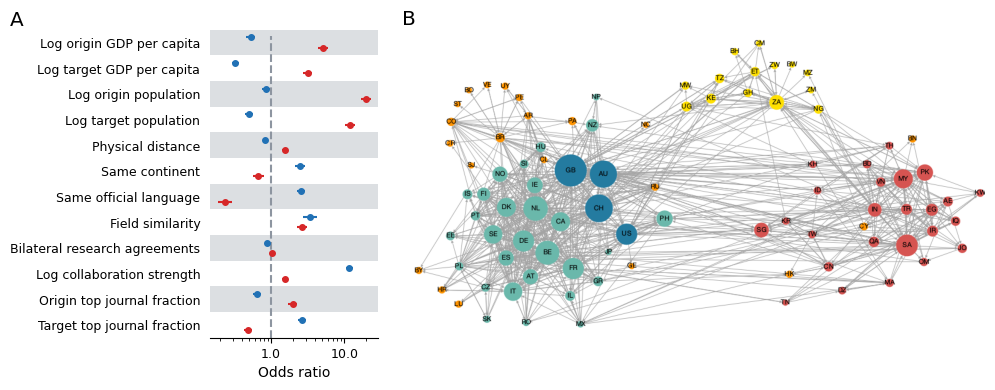

In [11]:
colours=['#8D95A0','#2171b5',sns.color_palette()[3]]

layout = [
    ["A", "B", "B", "B"]
]

fig, axd = plt.subplot_mosaic(layout, figsize=(10,4))


label = "A"
logistic_odds_ratio_plot(df1, df2, colours, ax=axd[label])

trans = mtransforms.ScaledTranslation(-2, 7/72, fig.dpi_scale_trans)
axd[label].text(0.0, 1.0, label, transform=axd[label].transAxes + trans,
                   fontsize='x-large', va='center')

from matplotlib.image import imread

# the journal bootstrap network (positive edges), drawn with the same layout as Fig. 2
label = "B"
bootnet_pic = imread(os.path.join(path2paperfigures, 'Fig4B_bootstrapnetwork.png'))
axd[label].imshow(bootnet_pic)
axd[label].axis('off')
trans = mtransforms.ScaledTranslation(-0.1, 7/72, fig.dpi_scale_trans)
axd[label].text(0.0, 1.0, label, transform=axd[label].transAxes + trans,
                   fontsize='x-large', va='bottom')

plt.savefig(os.path.join(path2figures, 'Fig4_bootstrapnetworkfeatures.pdf'), bbox_inches='tight')

plt.show()

## Source Data for Figure 4 and Supplementary Table 10

The data plotted in each panel, written to `Source Data/SourceData_4_Fig4.xlsx`, and the values reported in Supplementary Table 10, written to `Source Data/SourceData_10_TableS10.xlsx`.

In [12]:
# the Source Data helpers (sourcedatautils.py, in the code folder like vizutils.py)
from sourcedatautils import write_source_data, country2commlabel

title = 'Figure 4: The international network of scientific citation preferences controlling for publication journal.'
description = ('A) Odds ratios of the multinomial logit model with temporal fixed-effects (Model 6 of Supplementary '
               'Table 10) predicting a positive or negative journal bootstrap citation preference compared to no '
               'preference, with 95% confidence intervals; points are statistically significant at p <= 0.05. '
               'Continuous variables are standardized once over the 1990-2017 country-pair panel. The coefficients of '
               'all six models are given in SourceData_10_TableS10.xlsx. '
               'B) The cumulative journal bootstrap network (1990-2017) filtered to positive relationships: each directed '
               'edge from the citing country to the cited country is the most recent statistically significant positive '
               'journal bootstrap citation preference (N >= 50, Holm-Sidak correction with alpha = 0.01 within each '
               'year); node area is the in-degree and node colour the community (labelled 1-5 as in Fig. 2). ')

# A) the odds ratios of the final model
odds = []
for outcome, df in [('Positive', df1), ('Negative', df2)]:
    df = df[['item', 'odds_risk', 'odds_0', 'odds_1', 'risk', 'pvalues']].copy()
    df.columns = ['Variable', 'Odds ratio', 'CI lower (95%)', 'CI upper (95%)', 'Coefficient', 'p-value']
    df.insert(1, 'Citation preference', outcome)
    df['Significant (p <= 0.05)'] = df['p-value'] <= 0.05
    odds.append(df)
odds = pd.concat(odds, ignore_index=True)

# the coefficients and fit of all six models (Supplementary Table 10)
coefs = []
fits = []
for imodel, model in enumerate(fit_models):
    conf = model.conf_int()
    for icat, outcome in [(1, 'Positive'), (2, 'Negative')]:
        df = pd.DataFrame({'Coefficient':model.params[icat-1], 'SE':model.bse[icat-1], 'p-value':model.pvalues[icat-1]})
        df['CI lower (95%)'] = conf.loc[str(icat)]['lower']
        df['CI upper (95%)'] = conf.loc[str(icat)]['upper']
        df = df[~df.index.str.startswith('year_')]
        df.insert(0, 'Variable', df.index.map(lambda v: namedict.get(v, v)))
        df.insert(0, 'Citation preference', outcome)
        df.insert(0, 'Model', imodel + 1)
        coefs.append(df[['Model', 'Citation preference', 'Variable', 'Coefficient', 'CI lower (95%)', 'CI upper (95%)',
                         'SE', 'p-value']])
    fits.append([imodel + 1, int(model.nobs), model.prsquared, model.llf, model.llr, model.df_model, model.llr_pvalue])
coefs = pd.concat(coefs, ignore_index=True)
fits = pd.DataFrame(fits, columns=['Model', 'Observations', 'Pseudo R2', 'Log likelihood', 'LLR chi2', 'd.f.',
                                   'LLR p-value'])

# B) the positive journal bootstrap network
edge_columns = {'CitingCountry':'Citing country', 'CitedCountry':'Cited country', 'CitedYear':'Cited year',
                'AUC':'AUC', 'STD':'STD', 'N':'N', 'Zscore':'Z-score', 'pvalue':'p-value'}
pos_edges = pcumnet.sort_values(['CitingCountry', 'CitedCountry'])[list(edge_columns)].rename(columns=edge_columns)
pos_edges.insert(2, 'Citing community', pos_edges['Citing country'].map(country2commlabel))
pos_edges.insert(3, 'Cited community', pos_edges['Cited country'].map(country2commlabel))

countries = np.sort(np.unique(pcumnet[['CitingCountry', 'CitedCountry']].values.flatten()))
nodes = pd.DataFrame({'Country':countries})
nodes['Community'] = nodes['Country'].map(country2commlabel)
nodes['Positive in-degree'] = nodes['Country'].map(pcumnet['CitedCountry'].value_counts()).fillna(0).astype(int)

tables = [('A', 'A) Odds ratios of the positive and negative citation preference (Model 6).', odds),
          ('B nodes', 'B) Countries with their community and positive in-degree.', nodes),
          ('B edges', 'B) Positive edges of the cumulative journal bootstrap network.', pos_edges),
          ('N1 vs N2', 'Comparison of the original (N1) and journal bootstrap (N2) cumulative networks reported in the main text.', comparison)]

write_source_data('SourceData_4_Fig4.xlsx', title, description, tables)

# Supplementary Table 10: the coefficients and fit of all six models
title_s10 = 'Supplementary Table 10: Fixed-effect multinomial logit regression for 1990-2017 based on stratified bootstrap.'
description_s10 = ('Coefficients of the multinomial logit models (1)-(6) with temporal fixed-effects predicting a positive '
                   'or negative journal bootstrap citation preference compared to no preference (baseline). Continuous '
                   'variables are standardized once over the 1990-2017 country-pair panel. The year fixed effects are '
                   'included in all models but not shown.')
tables_s10 = [('Coefficients', 'Coefficients of each model for the positive and negative citation preference.', coefs),
              ('Model fit', 'Observations and goodness of fit of each model.', fits)]
write_source_data('SourceData_10_TableS10.xlsx', title_s10, description_s10, tables_s10)

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_4_Fig4.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_10_TableS10.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
